# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [14]:
# loading relevant packages
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

## Exploratory Data Analysis  
- Load in the cleaned data

In [25]:
DATA_DIR = Path("data")
clean_path = DATA_DIR / "cleaned_aviation_data.csv"


def _bootstrap_clean(target_path: Path) -> pd.DataFrame:
    """Rebuild the cleaned dataframe from raw AviationData.csv."""
    raw_candidates = [p for p in DATA_DIR.rglob("*.csv")
                      if p.name.lower() == "aviationdata.csv"]
    if not raw_candidates:
        raise FileNotFoundError("AviationData.csv not found under data/")
    raw_path = raw_candidates[0]
    print("Rebuilding from raw:", raw_path)

    df = pd.read_csv(raw_path, low_memory=False, encoding="latin-1")

    # ---- filters ----
    df = df[df["Aircraft.Category"].astype("string").str.strip().str.lower()
              .eq("airplane")].copy()
    df = df[df["Amateur.Built"].astype("string").str.strip().str.lower()
              .eq("no")].copy()

    df["Event.Date"] = pd.to_datetime(df["Event.Date"], errors="coerce")
    df = df[df["Event.Date"] >= pd.Timestamp("1983-01-01")].copy()

    # ---- injury metrics ----
    inj_cols = ["Total.Fatal.Injuries", "Total.Serious.Injuries",
                "Total.Minor.Injuries", "Total.Uninjured"]
    for c in inj_cols:
        df[c] = pd.to_numeric(df[c], errors="coerce").fillna(0).clip(lower=0)

    df["Total.Aboard"] = df[inj_cols].sum(axis=1)
    df["Fatal.Serious.Injuries"] = df["Total.Fatal.Injuries"] + df["Total.Serious.Injuries"]
    df["Fatal.Serious.Ratio"] = np.where(
        df["Total.Aboard"] > 0,
        df["Fatal.Serious.Injuries"] / df["Total.Aboard"],
        np.nan,
    )
    df["Any.Fatal.Serious.Injury"] = df["Fatal.Serious.Injuries"] > 0

    # ---- Aircraft.damage + Is.Destroyed ----
    dmg = df["Aircraft.damage"].astype("string").str.strip().str.title()
    dmg = dmg.replace({"Nan": pd.NA, "None": pd.NA, "Unknown": pd.NA,
                       "Unk": pd.NA, "": pd.NA})
    df["Aircraft.damage"] = dmg
    df["Is.Destroyed"] = dmg.str.lower().map(
        {"destroyed": True, "substantial": False, "minor": False})
    df["Is.Destroyed.num"] = df["Is.Destroyed"].map({True: 1.0, False: 0.0})

    # ---- Make ----
    df["Make"] = (df["Make"].astype("string").str.strip().str.upper()
                    .replace(["NAN", "NONE", "UNKNOWN", "", "UNK"], pd.NA))
    df["Make"] = df["Make"].replace({
        "MCDONNELL-DOUGLAS": "MCDONNELL DOUGLAS",
        "MCDONNELL DOUGLAS CORP": "MCDONNELL DOUGLAS",
        "MCDONNELL DOUGLAS CORPORATION": "MCDONNELL DOUGLAS",
        "BEECH AIRCRAFT": "BEECH", "BEECH AIRCRAFT CORP": "BEECH",
        "BEECHCRAFT": "BEECH",
        "CESSNA AIRCRAFT": "CESSNA",
        "PIPER AIRCRAFT": "PIPER",
        "AIR TRACTOR INC": "AIR TRACTOR",
        "AIR TRACTOR, INC.": "AIR TRACTOR",
    })
    counts = df["Make"].value_counts()
    df = df[df["Make"].isin(counts[counts >= 50].index)].copy()

    # ---- Model + Plane.Type ----
    df["Model"] = (df["Model"].astype("string").str.strip().str.upper()
                     .replace(["NAN", "NONE", "UNKNOWN", "", "UNK"], pd.NA))
    df = df.dropna(subset=["Model"]).copy()
    df["Plane.Type"] = df["Make"] + " " + df["Model"]

    # ---- other categoricals ----
    def _clean_cat(s):
        return s.astype("string").str.strip().str.upper().replace(
            ["UNK", "UNKNOWN", "NONE", "NAN", ""], pd.NA)
    for c in ["Engine.Type", "Weather.Condition",
              "Purpose.of.flight", "Broad.phase.of.flight"]:
        df[c] = _clean_cat(df[c])
    df["Number.of.Engines"] = pd.to_numeric(df["Number.of.Engines"], errors="coerce")
    df.loc[df["Number.of.Engines"] < 1, "Number.of.Engines"] = np.nan

    # ---- column removal (>20,000 non-nulls) but ALWAYS keep derived cols ----
    must_keep = [
        "Event.Id", "Event.Date", "Make", "Model", "Plane.Type",
        "Aircraft.damage", "Is.Destroyed", "Is.Destroyed.num",
        "Total.Fatal.Injuries", "Total.Serious.Injuries",
        "Total.Minor.Injuries", "Total.Uninjured", "Total.Aboard",
        "Fatal.Serious.Injuries", "Fatal.Serious.Ratio",
        "Any.Fatal.Serious.Injury",
        "Weather.Condition", "Broad.phase.of.flight",
        "Engine.Type", "Number.of.Engines", "Purpose.of.flight",
    ]
    nn = df.notna().sum()
    keep_cols = [c for c in df.columns
                 if (nn[c] > 20000) or (c in must_keep)]
    df = df[keep_cols].copy()

    df.to_csv(target_path, index=False, encoding="utf-8")
    return df


# ---- Load OR rebuild (robust to empty / corrupt files) ----
clean = None
if clean_path.exists():
    try:
        clean = pd.read_csv(clean_path, encoding="utf-8", low_memory=False)
        if clean.empty or clean.shape[1] == 0:
            raise pd.errors.EmptyDataError("no columns parsed")
        print("Loaded existing:", clean_path)
    except (pd.errors.EmptyDataError, pd.errors.ParserError) as err:
        print(f"Cleaned file unreadable ({err}). Rebuilding...")
        clean_path.unlink(missing_ok=True)
        clean = None

if clean is None:
    clean = _bootstrap_clean(clean_path)
    print("Rebuilt and saved:", clean_path)

# ---- post-load safety checks ----
clean["Event.Date"] = pd.to_datetime(clean["Event.Date"], errors="coerce")

if "Is.Destroyed.num" not in clean.columns:
    if "Is.Destroyed" in clean.columns:
        clean["Is.Destroyed.num"] = clean["Is.Destroyed"].map(
            lambda x: 1.0 if str(x).lower() == "true"
                      else (0.0 if str(x).lower() == "false" else np.nan))
    else:
        clean["Is.Destroyed.num"] = np.nan

required = ["Total.Aboard", "Fatal.Serious.Ratio", "Is.Destroyed.num",
            "Make", "Plane.Type", "Event.Id",
            "Weather.Condition", "Broad.phase.of.flight"]
missing = [c for c in required if c not in clean.columns]
if missing:
    raise RuntimeError(f"Cleaned data missing columns {missing}. "
                       f"Delete {clean_path} and rerun.")

print("\nShape:", clean.shape)
print("\nNull counts on critical columns:")
print(clean[required].isna().sum())
clean.head()

Cleaned file unreadable (No columns to parse from file). Rebuilding...
Rebuilding from raw: data\AviationData.csv
Rebuilt and saved: data\cleaned_aviation_data.csv

Shape: (17917, 21)

Null counts on critical columns:
Total.Aboard                 0
Fatal.Serious.Ratio        778
Is.Destroyed.num          1146
Make                         0
Plane.Type                   0
Event.Id                     0
Weather.Condition         2693
Broad.phase.of.flight    15473
dtype: int64


,Event.Id,Event.Date,Aircraft.damage,Make,Model,Number.of.Engines,Engine.Type,Purpose.of.flight,Total.Fatal.Injuries,Total.Serious.Injuries,Total.Minor.Injuries,Total.Uninjured,Weather.Condition,Broad.phase.of.flight,Total.Aboard,Fatal.Serious.Injuries,Fatal.Serious.Ratio,Any.Fatal.Serious.Injury,Is.Destroyed,Is.Destroyed.num,Plane.Type
4150,20001214X42478,1983-03-18,Minor,BOEING,747,4.0,TURBO FAN,<NA>,0.0,0.0,0.0,588.0,VMC,TAXI,588.0,0.0,0.0,False,False,0.0,BOEING 747
4171,20001214X42331,1983-03-20,Destroyed,PIPER,PA-28-140,1.0,RECIPROCATING,PERSONAL,1.0,1.0,0.0,0.0,IMC,CRUISE,2.0,2.0,1.0,True,True,1.0,PIPER PA-28-140
4285,20001214X42672,1983-04-02,<NA>,DE HAVILLAND,DHC-6,2.0,TURBO PROP,SKYDIVING,1.0,0.0,0.0,4.0,VMC,STANDING,5.0,1.0,0.2,True,NaN,NaN,DE HAVILLAND DHC-6
6760,20001214X45013,1983-11-08,Minor,BOEING,727-200,3.0,TURBO FAN,<NA>,0.0,0.0,0.0,100.0,VMC,TAXI,100.0,0.0,0.0,False,False,0.0,BOEING 727-200
6806,20001214X45188,1983-11-13,Substantial,BEECH,C35,1.0,RECIPROCATING,PERSONAL,0.0,0.0,0.0,1.0,VMC,CLIMB,1.0,0.0,0.0,False,False,0.0,BEECH C35


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [26]:
# Split small vs large aircraft using estimated passengers aboard (threshold = 20)
small = clean[clean["Total.Aboard"] < 20].copy()
large = clean[clean["Total.Aboard"] >= 20].copy()

print(f"Small aircraft events: {len(small)}")
print(f"Large aircraft events: {len(large)}")

MIN_EVENTS = 30  # statistical robustness floor

def make_safety_summary(data, min_events=MIN_EVENTS):
    return (
        data.dropna(subset=["Make"])
            .groupby("Make")
            .agg(
                n_events=("Event.Id", "count"),
                mean_fatal_serious_ratio=("Fatal.Serious.Ratio", "mean"),
                median_fatal_serious_ratio=("Fatal.Serious.Ratio", "median"),
                destroyed_rate=("Is.Destroyed.num", "mean"),
            )
            .query("n_events >= @min_events")
            .sort_values("mean_fatal_serious_ratio")
    )

small_make_summary = make_safety_summary(small)
large_make_summary = make_safety_summary(large)

print("\n--- Small aircraft makes (top 10 safest by injury ratio) ---")
display(small_make_summary.head(10))

print("\n--- Large aircraft makes (top 10 safest by injury ratio) ---")
display(large_make_summary.head(10))

Small aircraft events: 17038
Large aircraft events: 879

--- Small aircraft makes (top 10 safest by injury ratio) ---


,n_events,mean_fatal_serious_ratio,median_fatal_serious_ratio,destroyed_rate
Make,,,,
MCDONNELL DOUGLAS,56,0.091014,0.0,0.105263
BOEING,714,0.141973,0.0,0.067183
AVIAT AIRCRAFT INC,76,0.164474,0.0,0.040000
MAULE,215,0.164806,0.0,0.041860
GRUMMAN ACFT ENG COR-SCHWEIZER,58,0.206897,0.0,0.017241
AYRES,52,0.215686,0.0,0.134615
STINSON,129,0.216408,0.0,0.023256
AVIAT,70,0.221429,0.0,0.100000
BELLANCA,219,0.222603,0.0,0.050459



--- Large aircraft makes (top 10 safest by injury ratio) ---


,n_events,mean_fatal_serious_ratio,median_fatal_serious_ratio,destroyed_rate
Make,,,,
MCDONNELL DOUGLAS,54,0.007682,0.0,0.108108
BOMBARDIER INC,44,0.028038,0.0,0.037037
BOEING,547,0.056771,0.0,0.096774
EMBRAER,78,0.065274,0.0,0.088889
AIRBUS,118,0.086249,0.0,0.169811


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

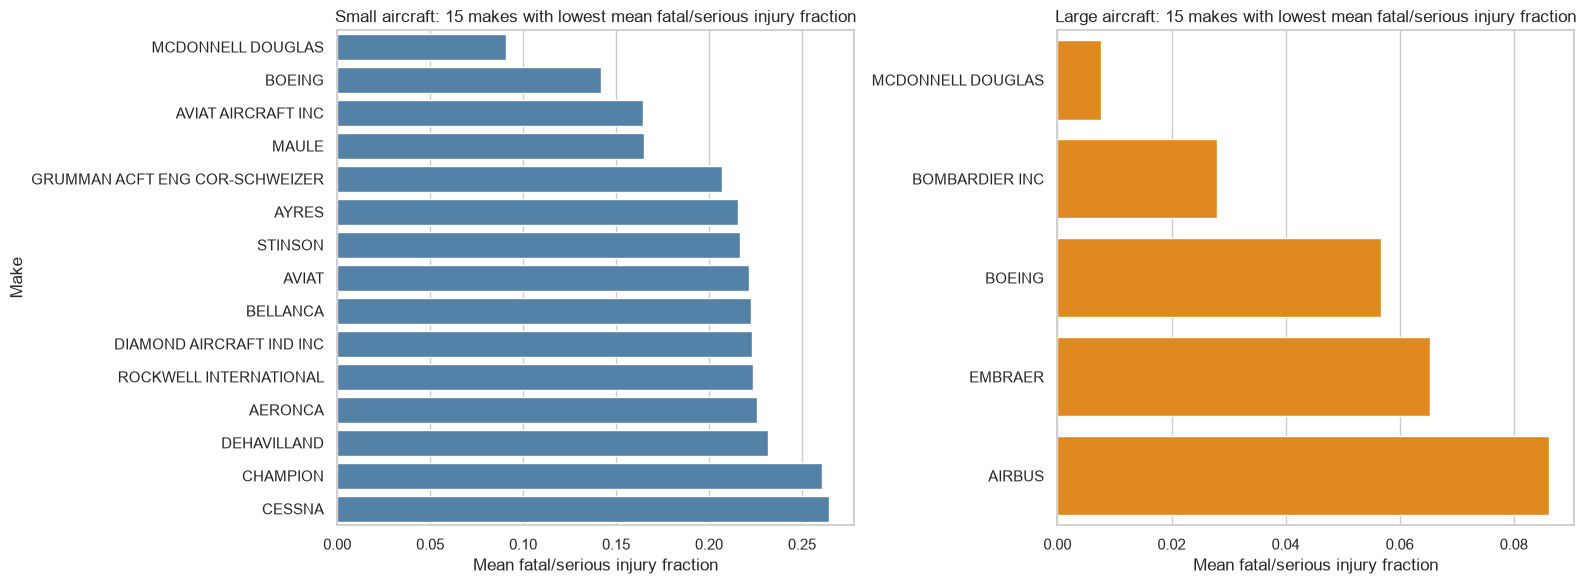

In [27]:
small_top15 = small_make_summary.head(15)
large_top15 = large_make_summary.head(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    data=small_top15.reset_index(),
    y="Make", x="mean_fatal_serious_ratio",
    ax=axes[0], color="steelblue",
)
axes[0].set_title("Small aircraft: 15 makes with lowest mean fatal/serious injury fraction")
axes[0].set_xlabel("Mean fatal/serious injury fraction")
axes[0].set_ylabel("Make")

sns.barplot(
    data=large_top15.reset_index(),
    y="Make", x="mean_fatal_serious_ratio",
    ax=axes[1], color="darkorange",
)
axes[1].set_title("Large aircraft: 15 makes with lowest mean fatal/serious injury fraction")
axes[1].set_xlabel("Mean fatal/serious injury fraction")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

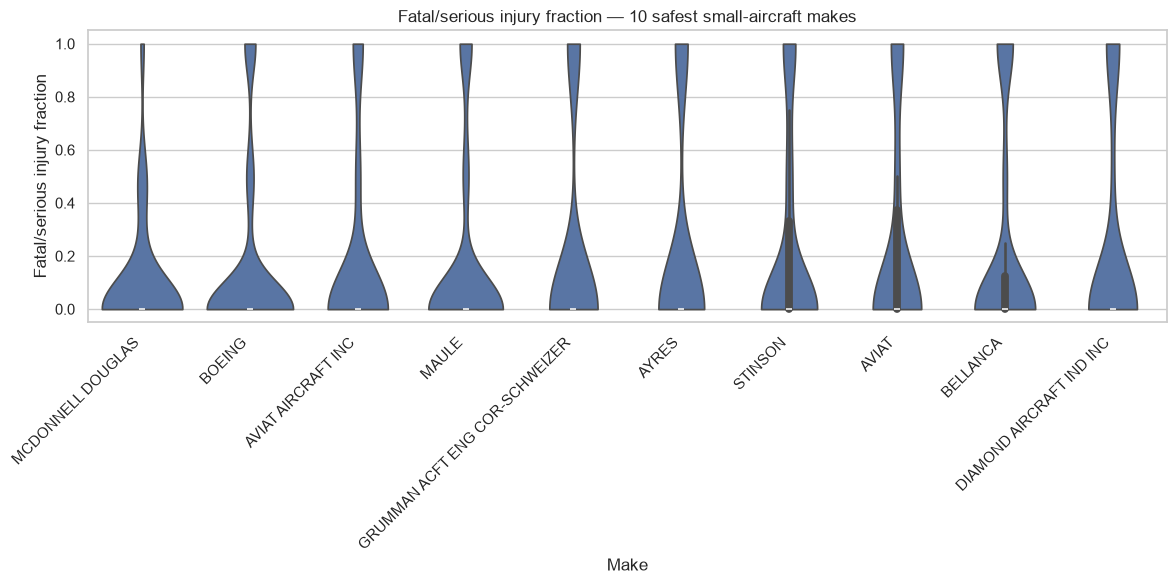

In [28]:
small_top10 = small_make_summary.head(10).index
small_plot = small.dropna(subset=["Fatal.Serious.Ratio"])
small_plot = small_plot[small_plot["Make"].isin(small_top10)]

plt.figure(figsize=(12, 6))
sns.violinplot(
    data=small_plot,
    x="Make", y="Fatal.Serious.Ratio",
    order=small_top10, cut=0,
)
plt.xticks(rotation=45, ha="right")
plt.title("Fatal/serious injury fraction — 10 safest small-aircraft makes")
plt.ylabel("Fatal/serious injury fraction")
plt.tight_layout()
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

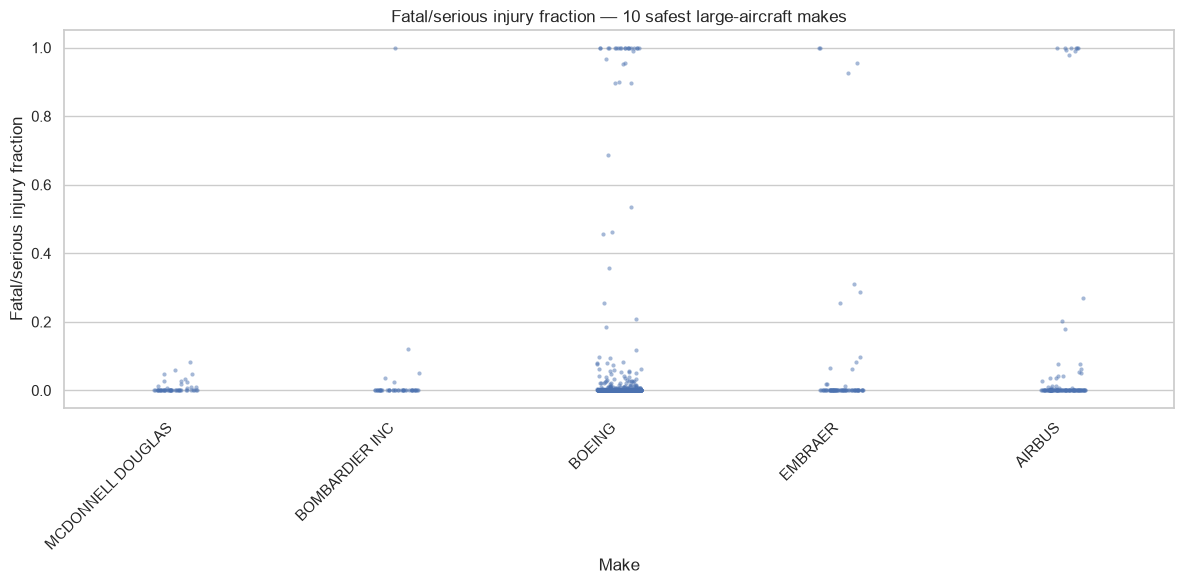

In [29]:
large_top10 = large_make_summary.head(10).index
large_plot = large.dropna(subset=["Fatal.Serious.Ratio"])
large_plot = large_plot[large_plot["Make"].isin(large_top10)]

plt.figure(figsize=(12, 6))
sns.stripplot(
    data=large_plot,
    x="Make", y="Fatal.Serious.Ratio",
    order=large_top10, jitter=True, alpha=0.5, size=3,
)
plt.xticks(rotation=45, ha="right")
plt.title("Fatal/serious injury fraction — 10 safest large-aircraft makes")
plt.ylabel("Fatal/serious injury fraction")
plt.tight_layout()
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

--- Small aircraft: destruction rate by make (lowest 15) ---


,n_events,destroyed_rate
Make,,
LUSCOMBE,138,0.014493
GRUMMAN ACFT ENG COR-SCHWEIZER,58,0.017241
STINSON,129,0.023256
TAYLORCRAFT,93,0.032258
AERONCA,200,0.035000
ERCOUPE,52,0.038462
AMERICAN CHAMPION AIRCRAFT,51,0.039216
AVIAT AIRCRAFT INC,75,0.040000
MAULE,215,0.041860



--- Large aircraft: destruction rate by make (lowest 15) ---


,n_events,destroyed_rate
Make,,
EMBRAER,45,0.088889
BOEING,279,0.096774
MCDONNELL DOUGLAS,37,0.108108
AIRBUS,53,0.169811


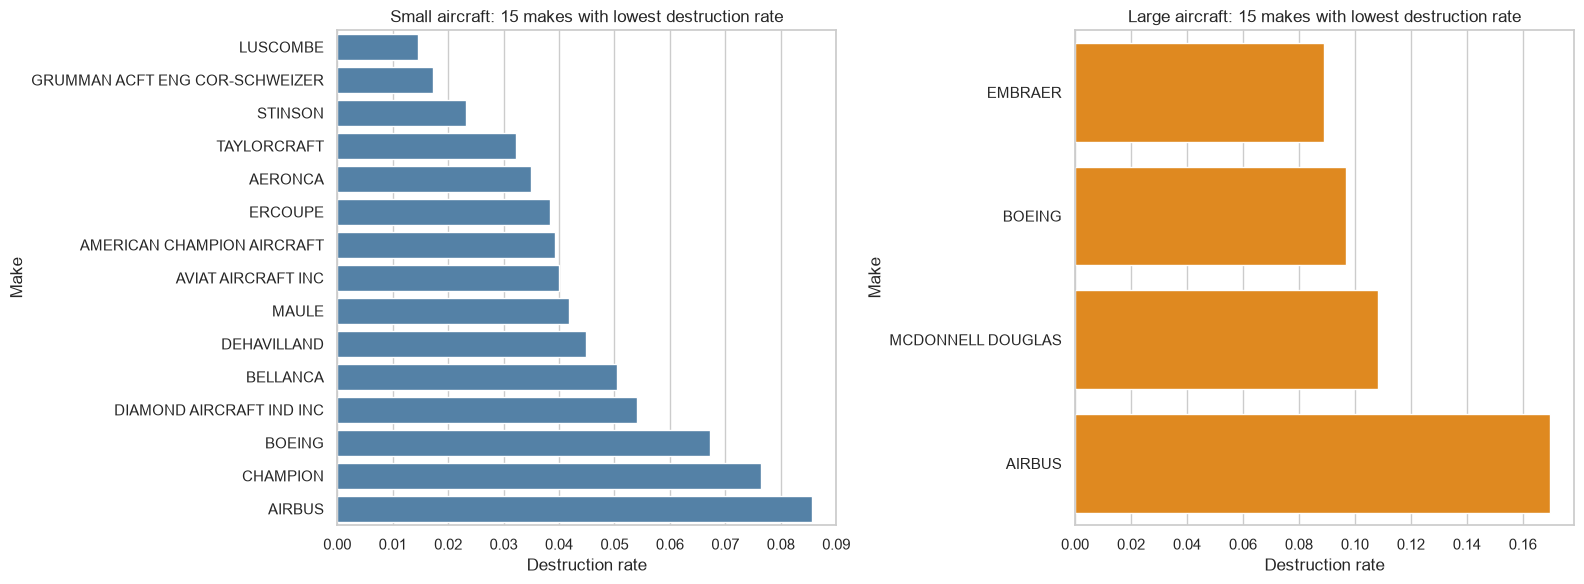

In [30]:
print("--- Small aircraft: destruction rate by make (lowest 15) ---")
small_destroyed = (
    small.dropna(subset=["Is.Destroyed.num"])
         .groupby("Make")
         .agg(
             n_events=("Event.Id", "count"),
             destroyed_rate=("Is.Destroyed.num", "mean"),
         )
         .query("n_events >= 30")
         .sort_values("destroyed_rate")
)
display(small_destroyed.head(15))

print("\n--- Large aircraft: destruction rate by make (lowest 15) ---")
large_destroyed = (
    large.dropna(subset=["Is.Destroyed.num"])
         .groupby("Make")
         .agg(
             n_events=("Event.Id", "count"),
             destroyed_rate=("Is.Destroyed.num", "mean"),
         )
         .query("n_events >= 30")
         .sort_values("destroyed_rate")
)
display(large_destroyed.head(15))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(data=small_destroyed.head(15).reset_index(),
            y="Make", x="destroyed_rate", ax=axes[0], color="steelblue")
axes[0].set_title("Small aircraft: 15 makes with lowest destruction rate")
axes[0].set_xlabel("Destruction rate")

sns.barplot(data=large_destroyed.head(15).reset_index(),
            y="Make", x="destroyed_rate", ax=axes[1], color="darkorange")
axes[1].set_title("Large aircraft: 15 makes with lowest destruction rate")
axes[1].set_xlabel("Destruction rate")
plt.tight_layout()
plt.show()

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

In [31]:
print("=" * 70)
print("SUMMARY OF MAKE-LEVEL FINDINGS")
print("=" * 70)

print("\n1. Safest SMALL makes (lowest mean fatal/serious injury fraction):")
print(small_make_summary.head(8)[["n_events","mean_fatal_serious_ratio","destroyed_rate"]])

print("\n2. Safest LARGE makes (lowest mean fatal/serious injury fraction):")
print(large_make_summary.head(8)[["n_events","mean_fatal_serious_ratio","destroyed_rate"]])

print("\n3. Safest SMALL makes (lowest destruction rate):")
print(small_destroyed.head(8))

print("\n4. Safest LARGE makes (lowest destruction rate):")
print(large_destroyed.head(8))

SUMMARY OF MAKE-LEVEL FINDINGS

1. Safest SMALL makes (lowest mean fatal/serious injury fraction):
                                n_events  mean_fatal_serious_ratio  destroyed_rate
Make                                                                              
MCDONNELL DOUGLAS                     56                  0.091014        0.105263
BOEING                               714                  0.141973        0.067183
AVIAT AIRCRAFT INC                    76                  0.164474        0.040000
MAULE                                215                  0.164806        0.041860
GRUMMAN ACFT ENG COR-SCHWEIZER        58                  0.206897        0.017241
AYRES                                 52                  0.215686        0.134615
STINSON                              129                  0.216408        0.023256
AVIAT                                 70                  0.221429        0.100000

2. Safest LARGE makes (lowest mean fatal/serious injury fraction):
   

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

Qualifying large plane types: 14


,n_events,mean_fatal_serious_ratio,destroyed_rate
Plane.Type,,,
BOEING 777,33,0.000821,0.062500
BOEING 757,18,0.001473,0.000000
BOEING 787,11,0.003058,0.000000
BOEING 737-7H4,12,0.003242,0.000000
BOMBARDIER INC CL-600-2B19,15,0.004136,0.000000
EMBRAER EMB145,11,0.008798,0.000000
EMBRAER EMB-145LR,15,0.010000,0.000000
BOEING 747,11,0.023161,0.000000
BOEING 767,31,0.046963,0.066667


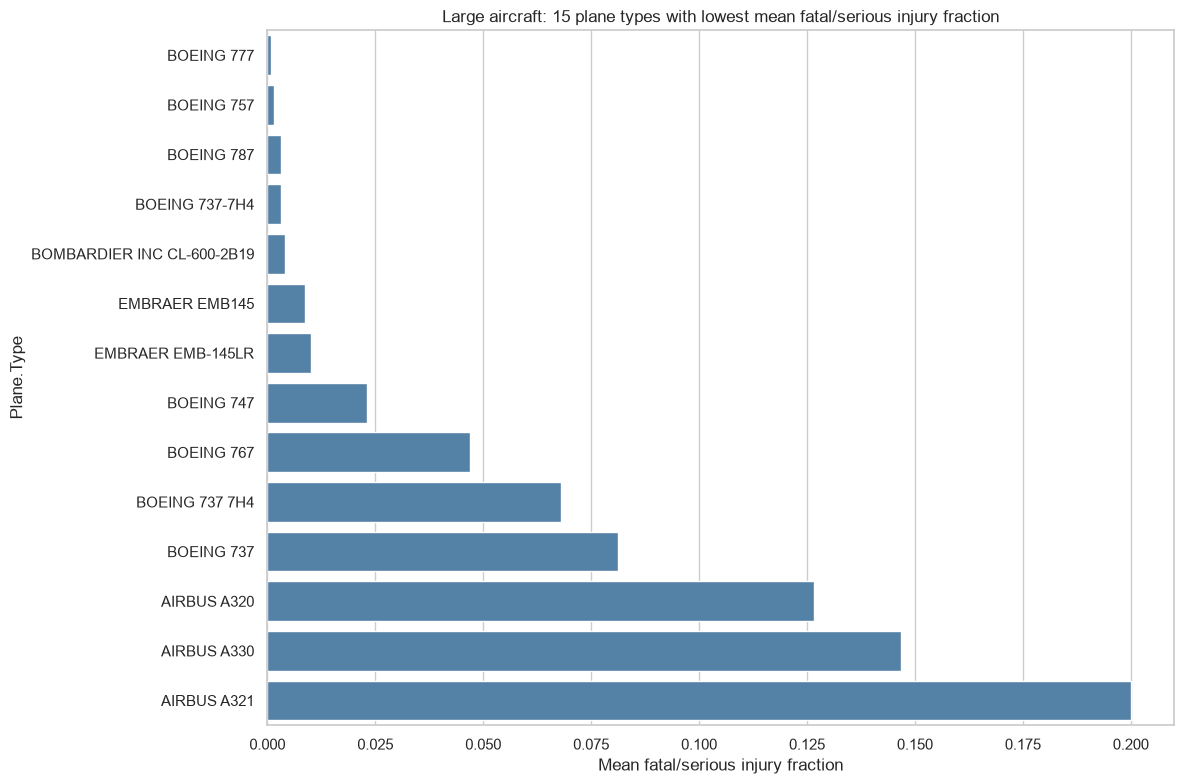

In [32]:
large_plane = large.dropna(subset=["Fatal.Serious.Ratio", "Plane.Type"])
plane_stats_large = (
    large_plane.groupby("Plane.Type")
               .agg(
                   n_events=("Event.Id", "count"),
                   mean_fatal_serious_ratio=("Fatal.Serious.Ratio", "mean"),
                   destroyed_rate=("Is.Destroyed.num", "mean"),
               )
               .query("n_events >= 10")   # at least 10 examples per plane type
               .sort_values("mean_fatal_serious_ratio")
)

print(f"Qualifying large plane types: {len(plane_stats_large)}")
display(plane_stats_large.head(20))

plt.figure(figsize=(12, 8))
sns.barplot(data=plane_stats_large.head(15).reset_index(),
            y="Plane.Type", x="mean_fatal_serious_ratio", color="steelblue")
plt.title("Large aircraft: 15 plane types with lowest mean fatal/serious injury fraction")
plt.xlabel("Mean fatal/serious injury fraction")
plt.tight_layout()
plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

,,n_events,mean_fatal_serious_ratio,destroyed_rate
Make,Plane.Type,,,
MAULE,MAULE M-5-210C,11,0.000000,0.000000
DIAMOND AIRCRAFT IND INC,DIAMOND AIRCRAFT IND INC DA 20 C1,11,0.000000,0.000000
BOEING,BOEING 747,26,0.076923,0.111111
STINSON,STINSON 108-1,16,0.083333,0.000000
BOEING,BOEING 737,36,0.083333,0.071429
BELLANCA,BELLANCA 7ECA,25,0.120000,0.000000
MAULE,MAULE MX7,18,0.125000,0.000000
BOEING,BOEING A75N1(PT17),31,0.139785,0.034483
AVIAT,AVIAT A-1B,21,0.142857,0.047619


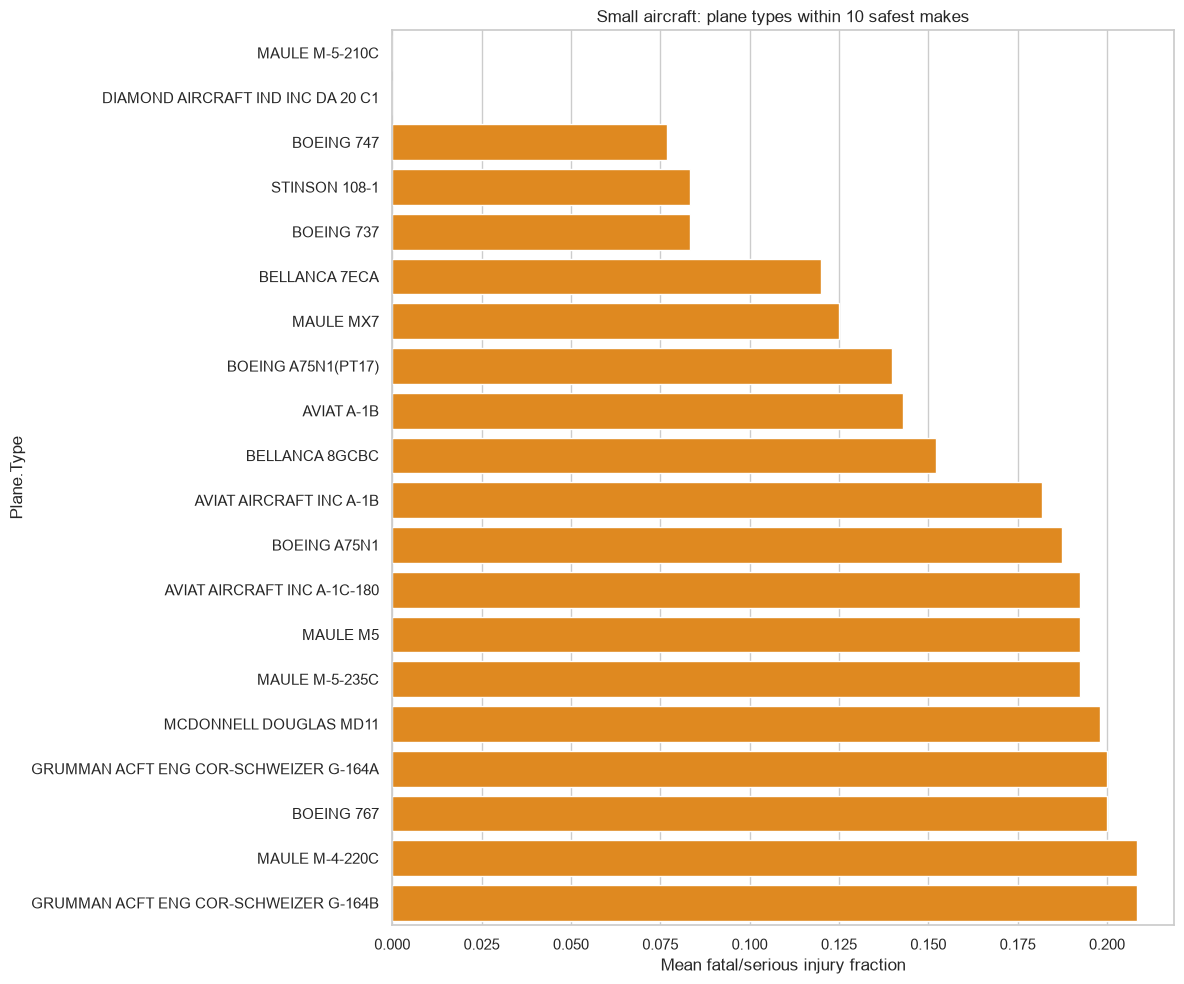

In [33]:
small_plane = small.dropna(subset=["Fatal.Serious.Ratio", "Plane.Type"])

plane_stats_small = (
    small_plane.groupby(["Make", "Plane.Type"])
               .agg(
                   n_events=("Event.Id", "count"),
                   mean_fatal_serious_ratio=("Fatal.Serious.Ratio", "mean"),
                   destroyed_rate=("Is.Destroyed.num", "mean"),
               )
               .query("n_events >= 10")
               .sort_values("mean_fatal_serious_ratio")
)

# Only keep plane types whose make is in the 10 safest small-aircraft makes
top_10_makes_small = small_make_summary.head(10).index
plane_stats_small_filtered = plane_stats_small.loc[
    plane_stats_small.index.get_level_values("Make").isin(top_10_makes_small)
]

display(plane_stats_small_filtered.head(30))

plt.figure(figsize=(12, 10))
sns.barplot(data=plane_stats_small_filtered.head(20).reset_index(),
            y="Plane.Type", x="mean_fatal_serious_ratio", color="darkorange")
plt.title("Small aircraft: plane types within 10 safest makes")
plt.xlabel("Mean fatal/serious injury fraction")
plt.tight_layout()
plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

In [34]:
print("=" * 70)
print("PLANE-TYPE FINDINGS")
print("=" * 70)
print("\nLarge aircraft — safest plane types (injury fraction):")
print(plane_stats_large.head(10)[["n_events","mean_fatal_serious_ratio","destroyed_rate"]])
print("\nLarge aircraft — safest plane types (destruction rate):")
print(plane_stats_large.sort_values("destroyed_rate").head(10))
print("\nSmall aircraft — safest plane types (injury fraction):")
print(plane_stats_small_filtered.sort_values("mean_fatal_serious_ratio").head(10)[["n_events","mean_fatal_serious_ratio","destroyed_rate"]])
print("\nSmall aircraft — safest plane types (destruction rate):")
print(plane_stats_small_filtered.sort_values("destroyed_rate").head(10))

PLANE-TYPE FINDINGS

Large aircraft — safest plane types (injury fraction):
                            n_events  mean_fatal_serious_ratio  destroyed_rate
Plane.Type                                                                    
BOEING 777                        33                  0.000821        0.062500
BOEING 757                        18                  0.001473        0.000000
BOEING 787                        11                  0.003058        0.000000
BOEING 737-7H4                    12                  0.003242        0.000000
BOMBARDIER INC CL-600-2B19        15                  0.004136        0.000000
EMBRAER EMB145                    11                  0.008798        0.000000
EMBRAER EMB-145LR                 15                  0.010000        0.000000
BOEING 747                        11                  0.023161        0.000000
BOEING 767                        31                  0.046963        0.066667
BOEING 737 7H4                    14                  0

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

FACTOR 1: WEATHER CONDITION


,n_events,mean_fatal_serious_ratio,destroyed_rate
Weather.Condition,,,
VMC,14317,0.233447,0.072668
IMC,907,0.628838,0.369034


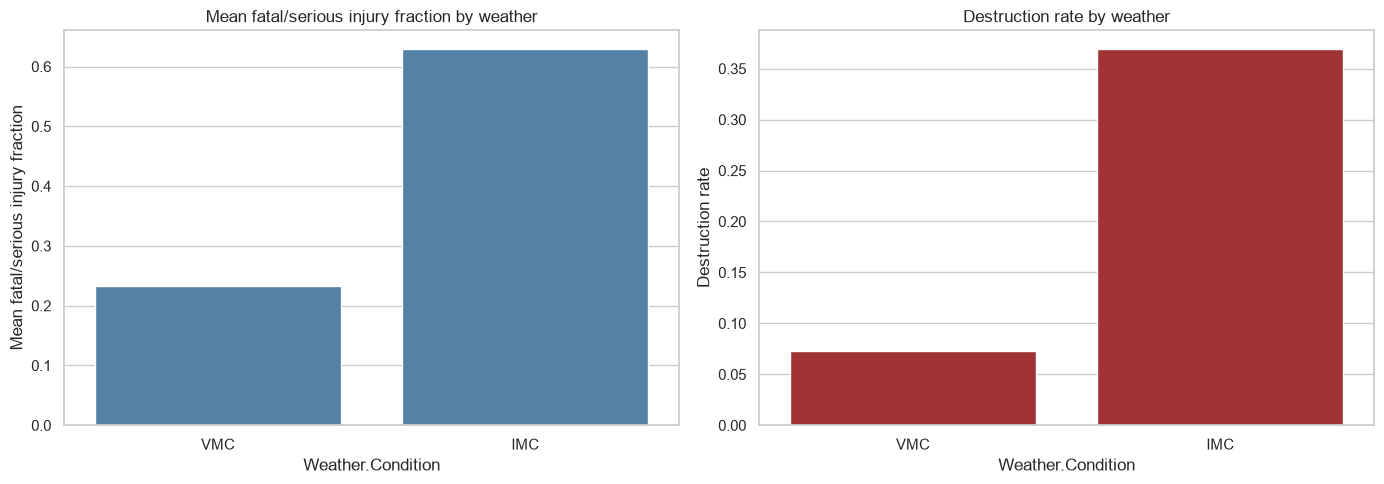

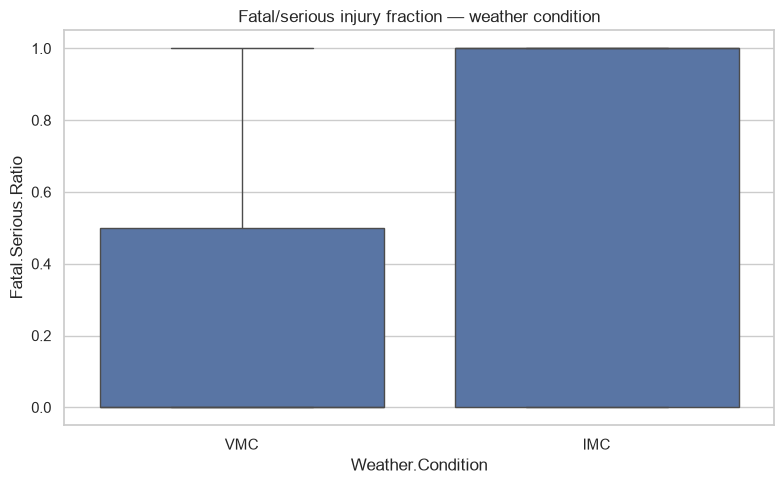

FACTOR 2: BROAD PHASE OF FLIGHT


,n_events,mean_fatal_serious_ratio,destroyed_rate
Broad.phase.of.flight,,,
MANEUVERING,127,0.358704,0.291339
APPROACH,210,0.213239,0.110577
CRUISE,239,0.186215,0.137339
TAKEOFF,426,0.110867,0.108235
LANDING,1111,0.008264,0.012601


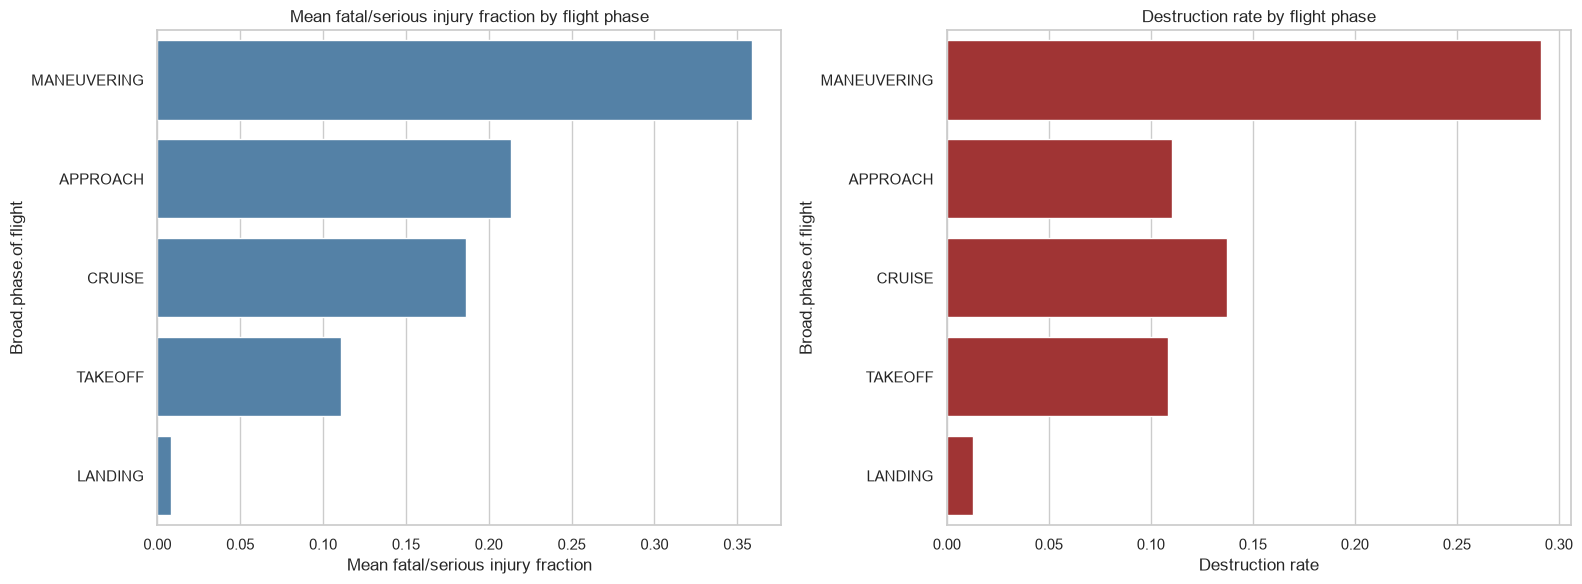

In [35]:
# ---------- Factor 1: Weather Condition ----------
print("=" * 70)
print("FACTOR 1: WEATHER CONDITION")
print("=" * 70)

weather_summary = (
    clean.dropna(subset=["Weather.Condition"])
         .groupby("Weather.Condition")
         .agg(
             n_events=("Event.Id", "count"),
             mean_fatal_serious_ratio=("Fatal.Serious.Ratio", "mean"),
             destroyed_rate=("Is.Destroyed.num", "mean"),
         )
         .query("n_events >= 100")
         .sort_values("n_events", ascending=False)
)
display(weather_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=weather_summary.reset_index(),
            x="Weather.Condition", y="mean_fatal_serious_ratio",
            ax=axes[0], color="steelblue")
axes[0].set_title("Mean fatal/serious injury fraction by weather")
axes[0].set_ylabel("Mean fatal/serious injury fraction")

sns.barplot(data=weather_summary.reset_index(),
            x="Weather.Condition", y="destroyed_rate",
            ax=axes[1], color="firebrick")
axes[1].set_title("Destruction rate by weather")
axes[1].set_ylabel("Destruction rate")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(data=clean.dropna(subset=["Weather.Condition", "Fatal.Serious.Ratio"]),
            x="Weather.Condition", y="Fatal.Serious.Ratio")
plt.title("Fatal/serious injury fraction — weather condition")
plt.tight_layout()
plt.show()

# ---------- Factor 2: Broad Phase of Flight ----------
print("=" * 70)
print("FACTOR 2: BROAD PHASE OF FLIGHT")
print("=" * 70)

phase_summary = (
    clean.dropna(subset=["Broad.phase.of.flight"])
         .groupby("Broad.phase.of.flight")
         .agg(
             n_events=("Event.Id", "count"),
             mean_fatal_serious_ratio=("Fatal.Serious.Ratio", "mean"),
             destroyed_rate=("Is.Destroyed.num", "mean"),
         )
         .query("n_events >= 100")
         .sort_values("mean_fatal_serious_ratio", ascending=False)
)
display(phase_summary)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(data=phase_summary.reset_index(),
            y="Broad.phase.of.flight", x="mean_fatal_serious_ratio",
            ax=axes[0], color="steelblue")
axes[0].set_title("Mean fatal/serious injury fraction by flight phase")
axes[0].set_xlabel("Mean fatal/serious injury fraction")

sns.barplot(data=phase_summary.reset_index(),
            y="Broad.phase.of.flight", x="destroyed_rate",
            ax=axes[1], color="firebrick")
axes[1].set_title("Destruction rate by flight phase")
axes[1].set_xlabel("Destruction rate")
plt.tight_layout()
plt.show()